# Introduction to Large Language Models

## Chain-of-Thought Prompting

Chain-of-Thought (CoT) is a multi-step prompting technique designed to elicit
more fully developed responses from large language models compared to standard
prompting approaches [Kojima et al., 2023](http://arxiv.org/abs/2205.11916);
[Wei et al., 2023](http://arxiv.org/abs/2201.11903). In this method, the prompt
is structured such that a step-by-step solution to an example problem is
provided before posing a similar question as input. By explicitly demonstrating
the intermediate reasoning steps—rather than presenting only the final
answer—the model is encouraged to follow a more deliberate reasoning process
[Wei et al., 2023](http://arxiv.org/abs/2201.11903). This approach is
particularly effective for improving performance on multi-step arithmetic and
reasoning tasks, while also offering greater interpretability into the internal
reasoning processes of the model (see Figure 1 below).

<div style="text-align: center;">
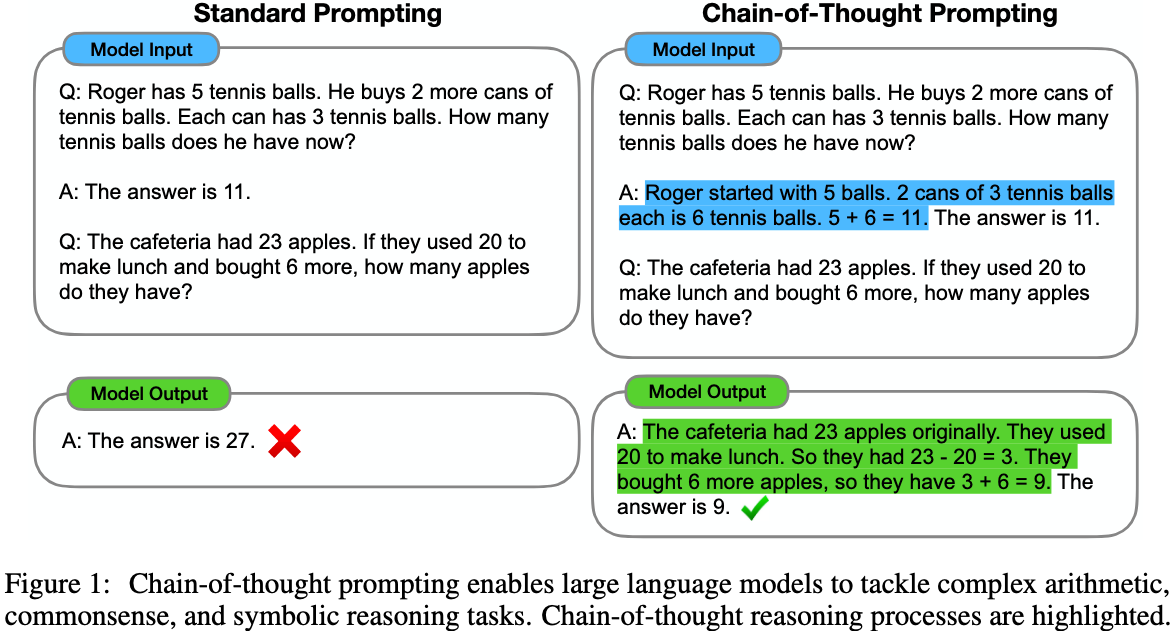
</div>

In addition to prompt formatting benefits, CoT reasoning provides a useful
mechanism for monitoring large language model outputs for potential exploits
that could lead to misaligned behavior [Baker et al.,
2025](http://arxiv.org/abs/2503.11926). Prior work has demonstrated that verbose
CoT outputs from stronger models (e.g., *o3-mini*) can be monitored using weaker
models (e.g., *GPT-4o*) to mitigate reward hacking behaviors [Baker et al.,
2025](http://arxiv.org/abs/2503.11926). However, excessive optimization may
allow models to learn to obscure their intent within the CoT itself, introducing
new avenues for hallucination and deceptive reasoning [Baker et al.,
2025](http://arxiv.org/abs/2503.11926); [OpenAI,
2025](http://arxiv.org/abs/2508.10925).


### From hand-written CoT to native reasoning

When [Wei et al.](http://arxiv.org/abs/2201.11903) and
[Kojima et al.](http://arxiv.org/abs/2205.11916) introduced chain-of-thought, it
was a *prompting trick*: you hand-wrote worked examples (or appended "let's think
step by step") to coax a model into reasoning out loud. Today's models have
largely **internalized** that behavior — frontier reasoning models generate their
own chain-of-thought before answering.

To see both worlds in one place, this lab uses
[**Qwen3-0.6B**](https://huggingface.co/Qwen/Qwen3-0.6B) — a compact (~0.6B
parameter) instruction-tuned model released in 2025. Despite being small enough
to run on a laptop CPU, it ships with a built-in **thinking mode**: the same
model can either answer directly *or* produce an explicit `<think>…</think>`
reasoning trace first, toggled with a single flag.

We replaced GPT-2 (2019, not instruction-tuned) with Qwen3-0.6B because GPT-2 is
no longer representative of even small modern models, and its CoT behavior is too
unreliable to learn from. Part 1 walks through three points on the timeline:

| Test | Mode | What it shows |
|------|------|---------------|
| 1 | Standard prompting | Direct question → direct answer |
| 2 | Manual chain-of-thought | Hand-written worked example (the 2022 trick) |
| 3 | Native thinking | The model writes its *own* reasoning (`enable_thinking=True`) |

> **Compute note:** the first run downloads the model (~1.2 GB). It runs on CPU;
> a GPU (or Google Colab's free GPU) just makes it faster.

In [1]:
# This lab uses the `uv` environment defined in the module folder.
# On Colab or a bare environment, install the dependencies directly instead:
# !pip install -U "transformers>=4.51" accelerate torch
#
# (Qwen3 support landed in transformers 4.51; this module pins a newer release.)

In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

# ANSI color codes for better visual distinction
BLUE = '\033[94m'
GREEN = '\033[92m'
RED = '\033[91m'
YELLOW = '\033[93m'
BOLD = '\033[1m'
RESET = '\033[0m'

# ============================================================================
# MODEL SELECTION - Qwen3 ships dense checkpoints from 0.6B up to 32B.
# ============================================================================
# We anchor this lab on the 0.6B model: small enough for a laptop CPU, yet a
# 2025-era instruction-tuned model with a built-in "thinking" mode. Uncomment a
# larger variant for stronger reasoning (Part 2 revisits the 1.7B and 4B sizes):
#
model_name = "Qwen/Qwen3-0.6B"      # ~0.6B - fast, CPU-friendly (this lab's default)
# model_name = "Qwen/Qwen3-1.7B"    # ~1.7B - stronger, still laptop-friendly
# model_name = "Qwen/Qwen3-4B"      # ~4B   - best quality here; prefer a GPU / Colab
# ============================================================================

print(f"Loading {model_name} ...")
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype="auto",        # bf16/fp16 where available, fp32 on CPU
    device_map="auto",   # use a GPU automatically if there is one
)
set_seed(42)
print("Loaded!")


def chat(prompt, enable_thinking=False, max_new_tokens=256, **gen_kwargs):
    """Send one user turn through the model's chat template.

    Returns (thinking, answer):
      - thinking: the model's internal reasoning (only when enable_thinking=True)
      - answer:   the final response a user would see
    """
    messages = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
    )
    model_inputs = tokenizer([text], return_tensors="pt").to(model.device)

    # Qwen3's own recommended sampling settings differ by mode.
    sampling = (
        dict(temperature=0.6, top_p=0.95, top_k=20)   # thinking
        if enable_thinking else
        dict(temperature=0.7, top_p=0.8, top_k=20)    # non-thinking
    )
    sampling.update(gen_kwargs)

    generated = model.generate(
        **model_inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        pad_token_id=tokenizer.eos_token_id,
        **sampling,
    )
    output_ids = generated[0][model_inputs.input_ids.shape[1]:].tolist()

    # Split off the </think> reasoning block, if the model produced one.
    think_close = tokenizer.convert_tokens_to_ids("</think>")
    try:
        split = len(output_ids) - output_ids[::-1].index(think_close)
    except ValueError:
        split = 0
    thinking = tokenizer.decode(output_ids[:split], skip_special_tokens=True).strip()
    answer = tokenizer.decode(output_ids[split:], skip_special_tokens=True).strip()
    return thinking, answer


def show(thinking, answer):
    """Pretty-print a (thinking, answer) pair from chat()."""
    if thinking:
        print(f"{YELLOW}🧠 Thinking:{RESET} {thinking}")
    print(f"{GREEN}💬 Answer:{RESET} {answer}")


# The arithmetic problem we'll reuse throughout Part 1
problem = "I have 3 oranges. I get 2 more oranges. How many oranges do I have now?"
print("=" * 80)
print(f"{BOLD}PROBLEM:{RESET} {problem}")
print(f"{BOLD}CORRECT ANSWER:{RESET} 5 oranges (3 + 2 = 5)")
print("=" * 80)

/Users/ppak/GitHub/CMU-AGT/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Qwen/Qwen3-0.6B ...


Loading weights: 100%|██████████| 311/311 [00:00<00:00, 480.59it/s]


Loaded!
PROBLEM: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?
CORRECT ANSWER: 5 oranges (3 + 2 = 5)


## Test 1: Standard Prompting (Direct Answer)

First, the baseline: ask the question with **no reasoning scaffolding** and
**thinking mode off** (`enable_thinking=False`). The model answers directly.
Even a 0.6B instruction-tuned model usually nails simple arithmetic here — a
sharp contrast with GPT-2, which often wandered off-topic.

In [3]:
print("=" * 80)
print(f"{RED}{BOLD}TEST 1: STANDARD PROMPTING (No Chain-of-Thought){RESET}")
print("=" * 80)

print(f"\n{BLUE}{BOLD}📝 PROMPT:{RESET} {problem}\n")

thinking, answer = chat(problem, enable_thinking=False, max_new_tokens=64)
show(thinking, answer)

TEST 1: STANDARD PROMPTING (No Chain-of-Thought)

📝 PROMPT: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?

💬 Answer: You start with 3 oranges. Then you get 2 more, so:

$$
3 + 2 = 5
$$

Now, you have **5 oranges**.


## Test 2: Manual Chain-of-Thought (Few-Shot)

Next, the **2022-era prompting trick**: still in non-thinking mode, but we
hand-write one worked example showing explicit reasoning, then pose a similar
question. This is *few-shot* chain-of-thought — the reasoning lives entirely in
the prompt the human wrote.

In [4]:
print("=" * 80)
print(f"{GREEN}{BOLD}TEST 2: MANUAL CHAIN-OF-THOUGHT (Few-Shot){RESET}")
print("=" * 80)

# A hand-written worked example, followed by the real question
cot_prompt = """Q: I have 2 apples. I get 3 more apples. How many apples do I have now?
A: I start with 2 apples. Then I get 3 more. So 2 + 3 = 5 apples.

Q: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?
A:"""

print(f"\n{BLUE}{BOLD}📝 FEW-SHOT CoT PROMPT:{RESET}")
print(f"{BLUE}{cot_prompt}{RESET}\n")

thinking, answer = chat(cot_prompt, enable_thinking=False, max_new_tokens=64)
show(thinking, answer)

print(f"\n{YELLOW}The worked example (2 + 3 = 5) teaches the model the pattern to apply{RESET}")
print(f"{YELLOW}to 3 + 2. The reasoning was supplied by us, in the prompt.{RESET}")

TEST 2: MANUAL CHAIN-OF-THOUGHT (Few-Shot)

📝 FEW-SHOT CoT PROMPT:
Q: I have 2 apples. I get 3 more apples. How many apples do I have now?
A: I start with 2 apples. Then I get 3 more. So 2 + 3 = 5 apples.

Q: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?
A:

💬 Answer: A: I start with 3 oranges. Then I get 2 more. So 3 + 2 = 5 oranges.

The worked example (2 + 3 = 5) teaches the model the pattern to apply
to 3 + 2. The reasoning was supplied by us, in the prompt.


## Test 3: Native Thinking Mode

Now the modern evolution. We flip `enable_thinking=True` and ask the **same plain
question** as Test 1 — no worked example. The model produces its *own*
`<think>…</think>` reasoning trace before committing to an answer. Chain-of-thought
has moved from something you hand-write into something the model does itself.

In [5]:
print("=" * 80)
print(f"{BOLD}TEST 3: NATIVE THINKING MODE (enable_thinking=True){RESET}")
print("=" * 80)

print(f"\n{BLUE}{BOLD}📝 PROMPT (no worked example this time):{RESET} {problem}\n")

# Thinking traces can run long, so give the model more room.
thinking, answer = chat(problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

print(f"\n{YELLOW}Notice the model generated its own step-by-step reasoning above —{RESET}")
print(f"{YELLOW}we never wrote one. That is the same CoT idea, now built into the model.{RESET}")

TEST 3: NATIVE THINKING MODE (enable_thinking=True)

📝 PROMPT (no worked example this time): I have 3 oranges. I get 2 more oranges. How many oranges do I have now?

🧠 Thinking: <think>
Okay, let me try to figure out this problem. So, the question is: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?

Hmm, let's break it down step by step. First, the initial number of oranges is given as 3. Then, there's a statement that says I get 2 more oranges. So, adding those two together should give the total number of oranges now.

Wait, let me make sure I'm not missing anything here. The problem doesn't mention any other oranges or any other actions, just adding two more. So, starting with 3, adding 2. That should be straightforward. 

Let me think of a simple way to represent this. If I have 3 and I add 2, it's like 3 + 2. Adding 2 to 3 would result in 5. So, now I have 5 oranges total.

Is there any chance that there's a trick here? Like maybe the question is trying to t

## Comparison and Analysis

Three points on the same timeline, all from one 0.6B model:

In [6]:
print("=" * 80)
print(f"{BOLD}📊 STANDARD vs MANUAL CoT vs NATIVE THINKING{RESET}")
print("=" * 80)

print(f"\n{RED}1. Standard prompting:{RESET}")
print(f"   • Direct question → direct answer, no reasoning shown")
print(f"   • Fine for easy questions; fragile as problems get harder")

print(f"\n{GREEN}2. Manual chain-of-thought (few-shot):{RESET}")
print(f"   • A human writes a worked example into the prompt")
print(f"   • The 2022 technique (Wei et al., Kojima et al.)")
print(f"   • Effective, but you must craft examples for every task")

print(f"\n{BLUE}3. Native thinking mode:{RESET}")
print(f"   • The model generates its own <think>…</think> reasoning")
print(f"   • No hand-written examples required")
print(f"   • How modern reasoning models work by default")

print(f"\n{YELLOW}{BOLD}Key insight:{RESET}")
print(f"{YELLOW}Chain-of-thought didn't disappear — it got absorbed into the model.{RESET}")
print(f"{YELLOW}The skill shifted from 'write clever prompts' to 'know when to spend{RESET}")
print(f"{YELLOW}the extra reasoning compute'.{RESET}")
print("=" * 80)

📊 STANDARD vs MANUAL CoT vs NATIVE THINKING

1. Standard prompting:
   • Direct question → direct answer, no reasoning shown
   • Fine for easy questions; fragile as problems get harder

2. Manual chain-of-thought (few-shot):
   • A human writes a worked example into the prompt
   • The 2022 technique (Wei et al., Kojima et al.)
   • Effective, but you must craft examples for every task

3. Native thinking mode:
   • The model generates its own <think>…</think> reasoning
   • No hand-written examples required
   • How modern reasoning models work by default

Key insight:
Chain-of-thought didn't disappear — it got absorbed into the model.
The skill shifted from 'write clever prompts' to 'know when to spend
the extra reasoning compute'.


## Test 4: Factual Knowledge & Reasoning

Does letting the model think improve factual answers? We ask the same question
with thinking **off** then **on**, and compare.

In [7]:
print("=" * 80)
print(f"{BOLD}TEST 4: FACTUAL KNOWLEDGE & REASONING{RESET}")
print("=" * 80)

factual_problem = "How many legs does a spider have?"
print(f"\n{BLUE}{BOLD}Question:{RESET} {factual_problem}")

print(f"\n{RED}Without thinking:{RESET}")
thinking, answer = chat(factual_problem, enable_thinking=False, max_new_tokens=64)
show(thinking, answer)

print(f"\n{GREEN}With thinking:{RESET}")
thinking, answer = chat(factual_problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

print(f"\n{YELLOW}Thinking mode reasons through the fact (spiders are arachnids → 8 legs){RESET}")
print(f"{YELLOW}rather than pattern-matching to a single token.{RESET}")

TEST 4: FACTUAL KNOWLEDGE & REASONING

Question: How many legs does a spider have?

Without thinking:
💬 Answer: A spider has **eight legs**.

With thinking:
🧠 Thinking: <think>
Okay, so the user is asking how many legs a spider has. Let me think. I remember that spiders are arachnids, right? They have eight legs. But wait, I should confirm this. Let me visualize a spider. A spider's body is made of a body segment, legs, and an abdomen. Each leg is a pair, so that's four legs. Oh, but sometimes people think they have more legs. Maybe they confuse them with other animals? Like, a spider's legs are actually four. So, the answer should be four legs. But maybe I should mention that it's a common misconception because of the number of legs. Also, maybe the user is trying to test if they know the correct answer. I should make sure to state the correct number and explain why it's correct. No, the question is straightforward, so just answer four.
</think>
💬 Answer: A spider has **four legs**. E

## Test 5: Hallucination Detection

A good model should refuse to invent facts that weren't given. Here the question
asks about *green* balloons when only red and blue were mentioned. Watch whether
thinking mode helps the model notice the information is missing.

In [8]:
print("=" * 80)
print(f"{BOLD}TEST 5: HALLUCINATION DETECTION{RESET}")
print("=" * 80)

halluc_problem = "Sarah has 5 red balloons and 3 blue balloons. How many green balloons does Sarah have?"
print(f"\n{BLUE}{BOLD}Question:{RESET} {halluc_problem}")

print(f"\n{RED}Without thinking:{RESET}")
thinking, answer = chat(halluc_problem, enable_thinking=False, max_new_tokens=80)
show(thinking, answer)

print(f"\n{GREEN}With thinking:{RESET}")
thinking, answer = chat(halluc_problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

print(f"\n{YELLOW}The information needed (green balloons) was never given. A reliable{RESET}")
print(f"{YELLOW}model says so instead of inventing a number — thinking makes that{RESET}")
print(f"{YELLOW}'no information' check explicit.{RESET}")

TEST 5: HALLUCINATION DETECTION

Question: Sarah has 5 red balloons and 3 blue balloons. How many green balloons does Sarah have?

Without thinking:
💬 Answer: Sarah has 5 red balloons and 3 blue balloons. So, the total number of balloons is:

$$
5 + 3 = 8
$$

Since the question asks how many **green** balloons Sarah has, and there are no mention of green balloons in the problem, we assume the answer is:

$$
\boxed{0}
$$

**Answer:** 0 green balloons

With thinking:
💬 Answer: <think>
Okay, let's see. Sarah has 5 red balloons and 3 blue balloons. The question is asking how many green balloons she has. Hmm, so first, I need to figure out the total number of balloons she has before she starts adding green ones. 

Alright, let me start by adding up the red and blue balloons. Red balloons are 5 and blue ones are 3. So, 5 plus 3... that should be 8. Let me check again. 5 plus 3... 5+3 is 8. Yeah, that makes sense. So if she has 5 red and 3 blue, the total is 8 balloons. 

But wait, the questi

## Test 6: Brittleness (Robustness to Phrasing)

A robust model gives the *same* answer when a problem is reworded. We ask one
subtraction problem two ways and check for consistency, with and without
thinking.

In [9]:
print("=" * 80)
print(f"{BOLD}TEST 6: BRITTLENESS (Robustness to Phrasing){RESET}")
print("=" * 80)

phrasing1 = "If I start with 4 cookies and eat 1, how many cookies remain?"
phrasing2 = "I have 4 cookies. I consume 1 cookie. How many cookies are left?"
print(f"\n{YELLOW}Same problem, two phrasings (answer should be 3 both times):{RESET}")
print(f"  1. {phrasing1}")
print(f"  2. {phrasing2}")

print(f"\n{RED}Without thinking:{RESET}")
for i, p in enumerate([phrasing1, phrasing2], 1):
    _, answer = chat(p, enable_thinking=False, max_new_tokens=48)
    print(f"  Phrasing {i}: {answer}")

print(f"\n{GREEN}With thinking:{RESET}")
for i, p in enumerate([phrasing1, phrasing2], 1):
    _, answer = chat(p, enable_thinking=True, max_new_tokens=512)
    print(f"  Phrasing {i}: {answer}")

print(f"\n{YELLOW}Brittleness = the answer changing when only the wording changes.{RESET}")
print(f"{YELLOW}Reasoning models tend to stay consistent across phrasings.{RESET}")

TEST 6: BRITTLENESS (Robustness to Phrasing)

Same problem, two phrasings (answer should be 3 both times):
  1. If I start with 4 cookies and eat 1, how many cookies remain?
  2. I have 4 cookies. I consume 1 cookie. How many cookies are left?

Without thinking:
  Phrasing 1: If you start with **4 cookies** and eat **1**, then:

- You eat 1, so you have **3** cookies left.

**Answer:** 3 cookies remain.
  Phrasing 2: You have 4 cookies. You consume 1 cookie. 

So, the number of cookies left is:

$$
4 - 1 = 3
$$

**Answer: 3 cookies are left.**

With thinking:
  Phrasing 1: If you start with 4 cookies and eat 1, the number of cookies remaining is calculated by subtracting the amount eaten from the initial number. 

$$ 4 - 1 = 3 $$

Therefore, the number of cookies remaining is **3**. 

$$
\boxed{3}
$$
  Phrasing 2: You start with 4 cookies and consume 1. To find out how many are left, subtract the number of cookies consumed from the total:

$$
4 - 1 = 3
$$

**Answer:** 3 cookies are lef

## Summary and Next Steps

You've compared three ways of getting a small model to reason, all with the same
**Qwen3-0.6B**:

### Key findings
1. **Standard prompting** handles easy questions but offers no reasoning to inspect.
2. **Manual CoT** (the 2022 trick) works, but you must hand-write examples per task.
3. **Native thinking mode** produces the model's own chain-of-thought — the modern default.
4. **Reasoning helps reliability**: factual recall, refusing to hallucinate, and
   consistency across phrasings all tend to improve when the model thinks first.

### Why a small model is still a good teacher
- It runs on a laptop, so you can iterate quickly and cheaply.
- Its limits are *visible*: on harder problems even a thinking 0.6B model slips,
  which is exactly what motivates (a) larger models and (b) **giving models tools**
  — the subject of **Lab 1.2: Why Agents Need Tools**.

### Next: does scale change the picture?
**Part 2** runs the same prompts through larger Qwen3 checkpoints (1.7B, 4B) so you
can see how reasoning quality scales — using the *same* `chat()` helper.

# Part 2: Scaling Up — Comparing Across Model Sizes

Part 1 used the smallest Qwen3 checkpoint. Because every size in the family shares
the same chat template and thinking toggle, we can reuse the **exact same `chat()`
helper** and prompts, and change only the model — isolating the effect of *scale*.

We climb a ladder:

| Stage | Model | ~Params | Runs comfortably on |
|-------|-------|---------|---------------------|
| Part 1 | `Qwen/Qwen3-0.6B` | 0.6B | Laptop CPU |
| Part 2a | `Qwen/Qwen3-1.7B` | 1.7B | Laptop CPU (slower) / any GPU |
| Part 2b | `Qwen/Qwen3-4B`   | 4B   | GPU or Google Colab recommended |

### 🌐 Faster option: try a browser interface first
Before downloading larger models, you can paste these same prompts into a hosted
chat UI and compare instantly — e.g. **Claude** (claude.ai), **ChatGPT**
(chat.openai.com), or **Gemini** (gemini.google.com). Hosted frontier models are
the top rung of this ladder; we return to them in the final comparison.

### ☁️ Or run on Colab
If local RAM is tight, open this notebook in **Google Colab** and enable a GPU
under *Runtime → Change runtime type*. That keeps the hands-on code workflow while
avoiding local resource pressure.

## Qwen3-1.7B (mid-size)

Roughly 3× the parameters of the Part 1 model, still small enough to run locally.
We reassign `model` and `tokenizer`, then call the same `chat()` helper — no other
code changes.

**Resource notes:** ~3.5 GB download · runs on CPU (slower) or any GPU.

In [10]:
print("Loading Qwen/Qwen3-1.7B ... (~3.5 GB on first download)")
model_name = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype="auto",
    device_map="auto",
)
print("✓ Qwen3-1.7B loaded — chat() now points at the bigger model.")
print("=" * 80)

Loading Qwen/Qwen3-1.7B ... (~3.5 GB on first download)


Loading weights: 100%|██████████| 311/311 [00:02<00:00, 129.16it/s]


✓ Qwen3-1.7B loaded — chat() now points at the bigger model.


### Qwen3-1.7B: Arithmetic with Thinking

The same arithmetic problem from Part 1, now with native thinking on a larger model.

In [11]:
print("=" * 80)
print(f"{BOLD}QWEN3-1.7B: ARITHMETIC (with thinking){RESET}")
print("=" * 80)
print(f"{BLUE}Question:{RESET} {problem}\n")

thinking, answer = chat(problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

QWEN3-1.7B: ARITHMETIC (with thinking)
Question: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?

💬 Answer: <think>
Okay, let's see. The problem says I have 3 oranges, and then I get 2 more. So, I need to figure out how many oranges I have in total now. Hmm, this seems straightforward, but let me think through it step by step to make sure I don't make a mistake.

First, I start with 3 oranges. That's the initial amount. Then, the question is about getting 2 more. So, adding those two to the original three. In math terms, that would be 3 plus 2. Let me do the addition: 3 + 2 equals 5. So, the total number of oranges should be 5. 

Wait, but maybe I should check if there's any trick here. Sometimes problems can have hidden details or require a different approach. For example, are the oranges being given in a different context? Like, maybe they're being split or something? But the problem doesn't mention anything like that. It just says I have 3 oranges and then ge

### Qwen3-1.7B: Hallucination Detection

Does the larger model handle the missing-information trap more cleanly?

In [12]:
print("=" * 80)
print(f"{BOLD}QWEN3-1.7B: HALLUCINATION DETECTION{RESET}")
print("=" * 80)
print(f"{BLUE}Question:{RESET} {halluc_problem}\n")

thinking, answer = chat(halluc_problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

QWEN3-1.7B: HALLUCINATION DETECTION
Question: Sarah has 5 red balloons and 3 blue balloons. How many green balloons does Sarah have?

🧠 Thinking: <think>
Okay, let's see. Sarah has 5 red balloons and 3 blue balloons. The question is asking how many green balloons she has. Hmm, first, I need to figure out if there's any information given about green balloons. Let me check again.

The problem says Sarah has 5 red balloons and 3 blue balloons. It doesn't mention anything about green balloons. So, maybe the answer is zero? Because there's no mention of green balloons at all. But wait, sometimes these problems might have a trick. Let me make sure I'm not missing anything.

The question is straightforward: how many green balloons does Sarah have? Since the problem doesn't provide any information about green balloons, it's possible that the answer is zero. But maybe there's a different interpretation. For example, if there's a typo or if the question is part of a larger context where green ba

## Qwen3-4B (larger — GPU / Colab recommended)

The top *local* rung. At ~4B parameters this is noticeably stronger, but heavier:
prefer a GPU or Colab. The load is wrapped in `try/except` so the notebook keeps
going if you don't have the resources.

**Resource notes:** ~8 GB download · ~8–10 GB RAM/VRAM · slow on CPU.

In [13]:
model_name = "Qwen/Qwen3-4B"
print(f"Loading {model_name} ... (~8 GB download; needs a GPU or plenty of RAM)")
print("If this fails, skip to the final comparison below.\n")

try:
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        dtype="auto",
        device_map="auto",
    )
    print("✓ Qwen3-4B loaded — chat() now points at the 4B model.")
except Exception as e:  # noqa: BLE001 - teaching notebook, surface any failure
    print(f"❌ Could not load Qwen3-4B: {e}")
    print("This is usually insufficient RAM/VRAM. Skip to the final comparison.")
print("=" * 80)

Loading Qwen/Qwen3-4B ... (~8 GB download; needs a GPU or plenty of RAM)
If this fails, skip to the final comparison below.



Loading weights: 100%|██████████| 398/398 [00:05<00:00, 69.52it/s] 


✓ Qwen3-4B loaded — chat() now points at the 4B model.


### Qwen3-4B: Arithmetic with Thinking

In [14]:
print("=" * 80)
print(f"{BOLD}QWEN3-4B: ARITHMETIC (with thinking){RESET}")
print("=" * 80)
print(f"{BLUE}Question:{RESET} {problem}\n")

thinking, answer = chat(problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

QWEN3-4B: ARITHMETIC (with thinking)
Question: I have 3 oranges. I get 2 more oranges. How many oranges do I have now?

🧠 Thinking: <think>
Okay, let's see. The problem says, "I have 3 oranges. I get 2 more oranges. How many oranges do I have now?" Hmm, so I need to figure out the total number of oranges after adding more.

First, I start with 3 oranges. Then, I get 2 more. So, adding them together. Let me think. 3 plus 2 is 5. Wait, is that right? Let me check again. If I have 3 and then add 2, it should be 3 + 2 = 5. Yeah, that seems correct. But maybe I should break it down to be sure. 

So, if I have 3 oranges, that's like three separate oranges. Then, getting 2 more means adding two more to that group. So, 3 + 2. Let me count them. One, two, three, four, five. Yep, that's five. So the answer should be 5. 

Wait, is there any chance I could have misread the question? Like, maybe "get 2 more" could mean something else? But no, in math problems, when they say "get more," it usually m

### Qwen3-4B: Hallucination Detection

In [15]:
print("=" * 80)
print(f"{BOLD}QWEN3-4B: HALLUCINATION DETECTION{RESET}")
print("=" * 80)
print(f"{BLUE}Question:{RESET} {halluc_problem}\n")

thinking, answer = chat(halluc_problem, enable_thinking=True, max_new_tokens=512)
show(thinking, answer)

QWEN3-4B: HALLUCINATION DETECTION
Question: Sarah has 5 red balloons and 3 blue balloons. How many green balloons does Sarah have?

🧠 Thinking: <think>
Okay, let's see. The problem says Sarah has 5 red balloons and 3 blue balloons. The question is asking how many green balloons Sarah has. Hmm, so I need to figure out the number of green balloons she has.

First, I should check if there's any information given about green balloons. The problem mentions red and blue balloons, but not green. The question is about green, so maybe there's a trick here. Wait, sometimes these problems can be tricky. Maybe the answer is zero because there's no mention of green balloons? But maybe I need to check if there's a hidden detail.

Let me read the problem again carefully: "Sarah has 5 red balloons and 3 blue balloons. How many green balloons does Sarah have?" There's no mention of green balloons in the first sentence. So, unless there's some context I'm missing, like maybe a previous problem or a diag

## Final Comparison: Model Performance Summary

| Model | ~Params | Reasoning | Hallucination control | Cost to run |
|-------|---------|-----------|-----------------------|-------------|
| Qwen3-0.6B | 0.6B | Basic, but real CoT | Sometimes slips | Free, laptop CPU |
| Qwen3-1.7B | 1.7B | Clearer, steadier | Usually catches missing info | Free, laptop/GPU |
| Qwen3-4B | 4B | Strong | Reliable | GPU/Colab |
| Frontier (Claude, GPT, Gemini) | 100B+ | Best-in-class | Most reliable | Hosted API, paid |

### What scaled, and what didn't
- **Scaled with size:** cleaner reasoning, fewer arithmetic slips, more reliable
  refusal to hallucinate. Same prompts, same `chat()` — only the model changed.
- **Didn't need to change:** the *method*. Defining a task, fixing the prompts, and
  comparing models on quality / cost / latency is the transferable benchmarking
  skill — it works identically from a 0.6B local model up to a frontier API.

### The benchmarking takeaway
There is no single "best" model — only the best fit for a **quality × cost × latency**
budget. A 0.6B model that runs free on a laptop can be the right choice; so can a
hosted frontier model. Choosing well means measuring, which is exactly what you did
here.

### Next: Part 3 — Why Agents Need Tools
Even the 4B model is still just predicting text — one token at a time. Part 3
(below) opens up how that text is represented, starting with **tokenization** and
byte-pair encoding: the groundwork beneath every model you just benchmarked, and
the first step toward understanding where a bare language model ends and an
*agent* with **tools** begins.

# Part 3: Why Agents Need Tools


The example below shows a blog post from a ChatGPT 3 user where they uncovered
an interesting bug when comparing number sizes. In this example the user asks the
model which is larger, 9.11 or 9.9?

In response the model states that 9.11 is larger than 9.9.

[https://community.openai.com/t/why-9-11-is-larger-than-9-9-incredible/869824](https://community.openai.com/t/why-9-11-is-larger-than-9-9-incredible/869824)

<div style="width: 100%; text-align: center;">
  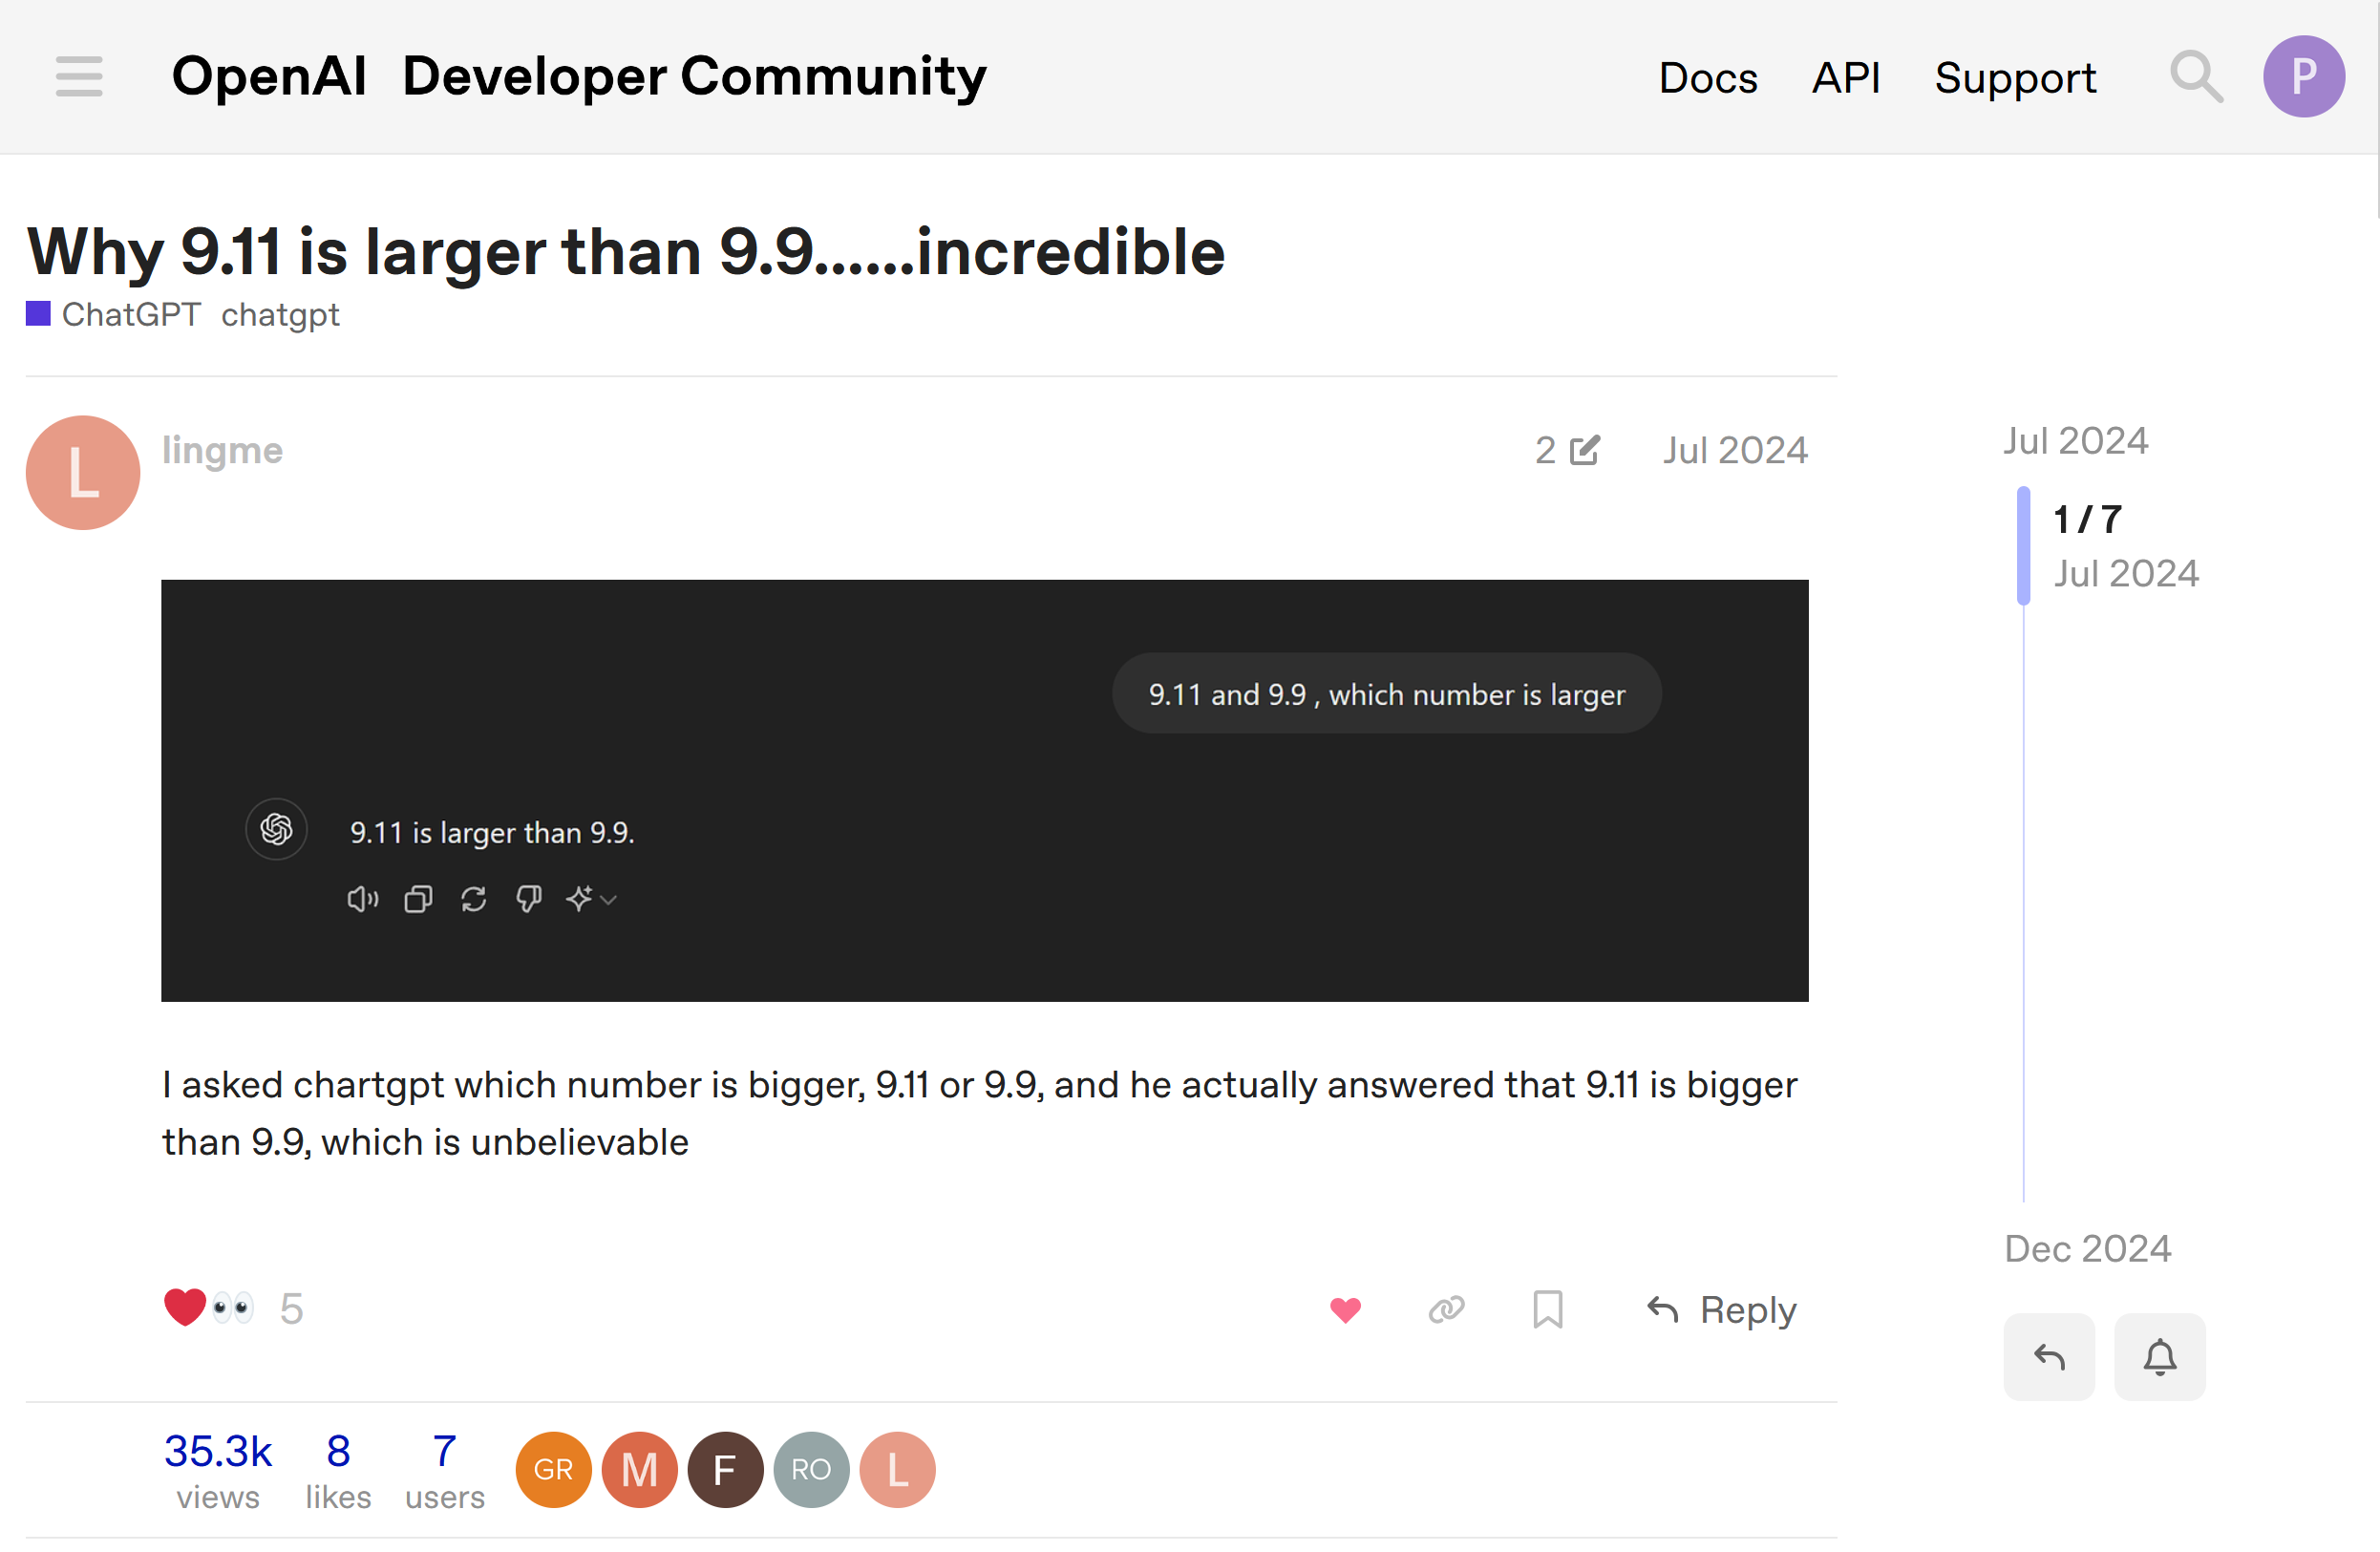
</div>


It is obvious that the model made an error, however what caused this error to occur in the first place?

To understand this, we'll need to review how the model sees text which is done in a process called **tokenization**.

## Tokenization
Tokenization is an essential component of the Natural Language Processing (NLP)
pipeline as it converts strings of human-readable characters into token
representations that are then embedded into vectors for the large language
model.  Raw text does not provide a suitable representation medium for models to
train as it commands a large vocabulary and treats words as distinct units.
Thus, tokenization presents a more efficient representation of the data to the
model as an embedding vector.  Tokenization methods include dividing character
strings into word and subword units, along with indexing frequently occurring
sequences detected using Byte Pair Encoding (BPE).  In order to retain
positional data, methods such as sinusoidal positional encoding or Rotary
Position Embeddings (RoPE) are added to the token embedding vectors.  By
converting the tokens to vector embeddings with positional data, the model is
able to use the semantic and sequential patterns of the input to perform next
token prediction from the representations learned during training.

Here's a nice interactive example showcasing how tokenization works.

[https://platform.openai.com/tokenizer](https://platform.openai.com/tokenizer)

Try inputting the previous prompt, what do you see?

### Byte Pair Encoding
Byte Pair Encoding was first introduced by Philip Gage as a method of data
compression useful in memory-constrained environments due to its fast expansion
routine. The compression routine of the algorithm looks for the most adjacent
byte pairs that occur most frequently within a given pass and replaces the pair
with a byte that doesn't already exist within the data. This repeats until there
are either no more frequent byte pairs or there are no more remaining unused
bytes. The expansion routine is performed over a single pass over the input
file, where byte literals are passed directly to the output buffer and byte
pairs are pushed onto a stack. Within each iteration, if the stack contains
data, the byte there is used as the next input byte; otherwise, the next input
byte is obtained from the input file.

In this exercise, you'll implement the BPE compression and expansion algorithms.

In [16]:
from string import ascii_letters, digits, punctuation
from typing import cast, TypedDict

characters = list(ascii_letters + digits + punctuation)

class BytePairTable(TypedDict):
    character: list[str]
    leftcode: list[str]
    rightcode: list[str | int]

def bpe_compression(input_string: str) -> tuple[BytePairTable, str]:
    byte_pair_table = BytePairTable(
        character = characters.copy(),
        leftcode = characters.copy(),
        rightcode = []
    )

    # Initial rightcode set
    for character in byte_pair_table["character"]:
        if character in input_string:
            byte_pair_table["rightcode"].append(1)
        else:
            byte_pair_table["rightcode"].append(0)

    buffer = input_string
    most_frequent_pair_value = None

    while most_frequent_pair_value is None or most_frequent_pair_value > 1:
        pair_map: dict[str, int] = {}
        buffer_length = len(buffer)

        for character_index in range(1, buffer_length):
            pair = buffer[character_index - 1] + buffer[character_index]

            if pair in pair_map:
                pair_map[pair] += 1
            else:
                pair_map[pair] = 1

        most_frequent_pair_value = max(pair_map.values())

        if most_frequent_pair_value > 1:
            most_frequent_pair_key: str = cast(str, max(pair_map, key=pair_map.get))

            # Find new character assignment.
            first_unused_character_index = next((i for i, v in enumerate(byte_pair_table["rightcode"]) if v == 0), None)
            if first_unused_character_index is None:
                # No more unused characters
                return (byte_pair_table, buffer)

            # Update table
            byte_pair_table["leftcode"][first_unused_character_index] = most_frequent_pair_key[0]
            byte_pair_table["rightcode"][first_unused_character_index] = most_frequent_pair_key[1]
            replacement_character = byte_pair_table["character"][first_unused_character_index]

            buffer = buffer.replace(most_frequent_pair_key, replacement_character)

    return (byte_pair_table, buffer)

def bpe_expansion(byte_pair_table: BytePairTable, buffer: str) -> str:

    input = list(buffer)
    input.reverse()

    stack: list[str] = []
    output_string = ""

    while len(input) > 0 or len(stack) > 0:
        if len(stack) > 0:
            character = stack.pop()
            character_index = byte_pair_table["character"].index(character)
            leftcode_value = byte_pair_table["leftcode"][character_index]
            rightcode_value = byte_pair_table["rightcode"][character_index]

            if rightcode_value == 1:
                output_string += character

            elif isinstance(rightcode_value, str):
                stack.append(rightcode_value)
                stack.append(leftcode_value)

        else:
            character = input.pop()
            stack.append(character)

    return output_string

# Test the BPE implementation
input_string = "ababcabcd"
print(f"input_string: {input_string}")

byte_pair_table, buffer = bpe_compression(input_string)
print(f"buffer: {buffer}")

output_string = bpe_expansion(byte_pair_table, buffer)
print(f"output_string: {output_string}")

input_string: ababcabcd
buffer: effd
output_string: ababcabcd


In [17]:
import unittest

class TestBPE(unittest.TestCase):
    def test_basic_round_trip(self):
        """Test that compression followed by expansion returns the original string."""
        input_string = "ababcabcd"
        byte_pair_table, compressed = bpe_compression(input_string)
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.1: Basic round trip - PASSED")

    def test_simple_repeated_pair(self):
        """Test compression with a simple repeated pair."""
        input_string = "aaaaaa"
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertLess(len(compressed), len(input_string))
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.2: Simple repeated pair - PASSED")

    def test_no_repeated_pairs(self):
        """Test string with no repeated pairs."""
        input_string = "abcdef"
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertEqual(compressed, input_string)
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.3: No repeated pairs - PASSED")

    def test_two_characters(self):
        """Test with two characters."""
        input_string = "ab"
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertEqual(compressed, input_string)
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.4: Two characters - PASSED")

    def test_multiple_compression_iterations(self):
        """Test that multiple iterations of compression work correctly."""
        input_string = "abababab"
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertLess(len(compressed), len(input_string))
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.5: Multiple compression iterations - PASSED")

    def test_nested_pairs(self):
        """Test compression with nested pair patterns."""
        input_string = "aabbccaabbcc"
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertLess(len(compressed), len(input_string))
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.6: Nested pairs - PASSED")

    def test_mixed_characters(self):
        """Test with mixed alphanumeric and punctuation."""
        input_string = "Hello!!World!!123123"
        byte_pair_table, compressed = bpe_compression(input_string)
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.7: Mixed characters - PASSED")

    def test_byte_pair_table_structure(self):
        """Test that the byte pair table has the correct structure."""
        input_string = "aabbcc"
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertIn("character", byte_pair_table)
        self.assertIn("leftcode", byte_pair_table)
        self.assertIn("rightcode", byte_pair_table)
        self.assertEqual(len(byte_pair_table["character"]), len(byte_pair_table["leftcode"]))
        self.assertEqual(len(byte_pair_table["character"]), len(byte_pair_table["rightcode"]))
        print("✓ Test 1.8: Byte pair table structure - PASSED")

    def test_rightcode_values(self):
        """Test that rightcode values are properly set."""
        input_string = "aabb"
        byte_pair_table, compressed = bpe_compression(input_string)
        char_index_a = byte_pair_table["character"].index("a")
        char_index_b = byte_pair_table["character"].index("b")
        self.assertNotEqual(byte_pair_table["rightcode"][char_index_a], 0)
        self.assertNotEqual(byte_pair_table["rightcode"][char_index_b], 0)
        print("✓ Test 1.9: Rightcode values - PASSED")

    def test_long_repeated_pattern(self):
        """Test with a longer repeated pattern."""
        input_string = "abcabc" * 10
        byte_pair_table, compressed = bpe_compression(input_string)
        self.assertLess(len(compressed), len(input_string))
        output = bpe_expansion(byte_pair_table, compressed)
        self.assertEqual(output, input_string)
        print("✓ Test 1.10: Long repeated pattern - PASSED")

# Run the tests
suite = unittest.TestLoader().loadTestsFromTestCase(TestBPE)
runner = unittest.TextTestRunner(verbosity=0)
result = runner.run(suite)

print(f"\n{'='*50}")
print(f"Tests run: {result.testsRun}")
print(f"Failures: {len(result.failures)}")
print(f"Errors: {len(result.errors)}")
if result.wasSuccessful():
    print("✓ All BPE tests passed!")
else:
    print("✗ Some tests failed")
print(f"{'='*50}")

----------------------------------------------------------------------
Ran 10 tests in 0.000s

OK


✓ Test 1.1: Basic round trip - PASSED
✓ Test 1.8: Byte pair table structure - PASSED
✓ Test 1.10: Long repeated pattern - PASSED
✓ Test 1.7: Mixed characters - PASSED
✓ Test 1.5: Multiple compression iterations - PASSED
✓ Test 1.6: Nested pairs - PASSED
✓ Test 1.3: No repeated pairs - PASSED
✓ Test 1.9: Rightcode values - PASSED
✓ Test 1.2: Simple repeated pair - PASSED
✓ Test 1.4: Two characters - PASSED

Tests run: 10
Failures: 0
Errors: 0
✓ All BPE tests passed!


### Test Your BPE Implementation

Run the tests below to verify your implementation works correctly:

### Subword Neural Machine Translation
Subword Neural Machine Translation is a preprocessing method in which text is
segmented into subword units, specifically useful for encoding out-of-vocabulary
(OOV) words. The approach implements an adapted version of Byte Pair Encoding
(BPE) to first generate the pair table for frequently occurring character
sequences within the training text. This is similar to the pair table seen in
the compressed output that the original BPE produces, but with a slight
adjustment of merging characters rather than bytes to suit the application of
word segmentation. Along with this, the compression routine is set to conclude
after a given number of operations rather than repeating until there are no more
remaining bytes in the text. This provides a tunable `num_operations` parameter
which balances the frequency for complete words and subwords within the
dictionary, improving the coverage of tokens during training. This allows
out-of-vocabulary words to be segmented into combinations of word and subword
tokens.


In [18]:
!pip install subword_nmt


[notice] A new release of pip is available: 26.0 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [19]:
from subword_nmt.learn_bpe import learn_bpe
from subword_nmt.apply_bpe import BPE
from subword_nmt.get_vocab import get_vocab
from subword_nmt.segment_char_ngrams import segment_char_ngrams
import io

def snmt_learn_bpe(text, num_operations=10):
    """
    Learn BPE operations from input text and return codes and segmented text.

    Args:
        text: Input text to segment
        num_operations: Number of BPE merge operations to learn

    Returns:
        Tuple of (bpe_codes, segmented_text):
            - bpe_codes: String containing learned BPE merge operations
            - segmented_text: Text segmented with BPE tokens separated by '@@'
    """
    # Learn BPE operations from the input text
    input_file = io.StringIO(text)
    output_file = io.StringIO()

    learn_bpe(input_file, output_file, num_symbols=num_operations)

    # Get the learned codes
    output_file.seek(0)
    codes = output_file.read()

    # Apply learned BPE operations
    output_file.seek(0)
    bpe = BPE(output_file)

    # Segment the text
    segmented = bpe.process_line(text)

    return codes, segmented


def snmt_apply_bpe(text, bpe_codes, vocab=None, vocab_threshold=None):
    """
    Apply pre-learned BPE codes to segment text.

    Args:
        text: Input text to segment
        bpe_codes: String containing BPE merge operations (one per line)
        vocab: Optional dict from snmt_get_vocab. If provided, reverts merges
               that produce out-of-vocabulary tokens.
        vocab_threshold: Optional frequency threshold. Tokens with frequency
                        below this are treated as OOV.

    Returns:
        Segmented text with BPE tokens separated by '@@'
    """
    codes_file = io.StringIO(bpe_codes)

    # Convert vocab dict to set, filtering by threshold if provided
    vocab_set = None
    if vocab is not None:
        if vocab_threshold is not None:
            vocab_set = {word for word, freq in vocab.items() if freq >= vocab_threshold}
        else:
            vocab_set = set(vocab.keys())

    bpe = BPE(codes_file, vocab=vocab_set)
    segmented = bpe.process_line(text)
    return segmented


def snmt_get_vocab(text):
    """
    Extract vocabulary with frequency counts from text.

    Args:
        text: Input text to extract vocabulary from

    Returns:
        Dictionary mapping tokens to their frequency counts
    """
    input_file = io.StringIO(text)
    output_file = io.StringIO()

    get_vocab(input_file, output_file)

    output_file.seek(0)
    vocab = {}
    for line in output_file:
        parts = line.strip().split()
        if len(parts) == 2:
            token, count = parts
            vocab[token] = int(count)
    return vocab


def snmt_segment_char_ngrams(text, n=3, vocab=None):
    """
    Segment text into character n-grams.

    Args:
        text: Input text to segment
        n: Size of character n-grams
        vocab: Optional vocabulary file-like object for shortlisting

    Returns:
        Segmented text with character n-grams
    """
    import argparse

    input_file = io.StringIO(text)
    output_file = io.StringIO()
    vocab_file = vocab if vocab else io.StringIO("")

    args = argparse.Namespace(
        input=input_file,
        output=output_file,
        n=n,
        shortlist=0,
        vocab=vocab_file,
        separator="@@"
    )

    segment_char_ngrams(args)

    output_file.seek(0)
    return output_file.read().strip()

You'll investigate the subword neural machine translation process by running the code below and answering the following questions:

**Question 1:** Before running the code, what tokens would you expect to be added to the vocabulary?

**Question 2:** After running the code, what are some tokens you found in the vocabulary and does that match your expectation?

**Question 3:** Let's take a look at the `num_operations` parameter, keep an eye on `codes` (indicated as "Learned codes:" in the print statement)

- **3a:** Change the `num_operations` to `50`, what do you notice with the vocabulary output?

- **3b:** Now change the `num_operations` to `1`, what do you notice with the vocabulary output?

- **3c:** Why does this happen?

- **3d:** Why use a limit such as `num_operations` as opposed to running this like the compression routine in BPE?

- **3e:** How did the `codes` change while you were changing the `num_operations`. What does `codes` look like what we've seen before in the homework?

**Question 4:** Now set `num_operations` back to `20` and examine the `vocab_threshold` parameter.

- **4a:** Change the `vocab_threshold` to `10`, what do you notice with the token count?

- **4b:** Why does this happen?

In [20]:
import re

# BPE codes will be obtained from this string
train_text = """The quick brown fox jumped over the lazy dog.
I ordered a hamburger from mcdonalds.
I ordered a cheeseburger from mcdonalds.
I ordered a double bacon cheeseburger from burger king.
I ordered a double-double from in-in-out burger.
How much wood could a woodchuck chuck if a woodchuck could chuck wood.
Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.
"""

input_text = "I ordered a burger and buffalo wings for Chuck" 

num_operations = 20
vocab_threshold = 2

# Step 1: Learn BPE codes from training text
print("=== Step 1: snmt_learn_bpe ===")
codes, segmented = snmt_learn_bpe(train_text, num_operations=num_operations)
print(f"Segmented: {segmented}")
print(f"Learned codes:\n{codes}")
print(f"Tokens: {len(segmented.split())}")

# Step 2: Get vocabulary from segmented text
print("=== Step 2: snmt_get_vocab ===")
vocab = snmt_get_vocab(segmented)
print(f"Vocabulary: {vocab}")
print(f"Vocab size: {len(vocab)}")

# Step 3: Apply BPE to new text (without vocab constraint)
print("\n=== Step 3a: snmt_apply_bpe (no vocab) ===")
result = snmt_apply_bpe(input_text, codes)
print(f"Input: {input_text}")
print(f"Segmented: {result}")
print(f"Tokens: {len(result.split())}")

# Step 3b: Apply BPE with vocab constraint (reverts OOV merges)
print(f"\n=== Step 3b: snmt_apply_bpe (with vocab, threshold={vocab_threshold}) ===")
result_with_vocab = snmt_apply_bpe(input_text, codes, vocab=vocab, vocab_threshold=vocab_threshold)
print(f"Input: {input_text}")
print(f"Segmented: {result_with_vocab}")
print(f"Tokens: {len(result_with_vocab.split())}")

# The original segmentation can be restored with a simple replacement:
# sed -r 's/(@@ )|(@@ ?$)//g'
print("\n=== Restore original from BPE ===")
restored = re.sub(r"(@@ )|(@@ ?$)", "", segmented)
print(f"Segmented: {segmented}")
print(f"Restored:  {restored}")

=== Step 1: snmt_learn_bpe ===


100%|██████████| 20/20 [00:00<00:00, 25282.12it/s]

Segmented: T@@ h@@ e q@@ u@@ i@@ c@@ k b@@ ro@@ w@@ n f@@ o@@ x j@@ u@@ m@@ p@@ ed o@@ v@@ e@@ r t@@ h@@ e l@@ a@@ z@@ y d@@ o@@ g@@ .@@ 
@@ I o@@ rde@@ red a h@@ a@@ m@@ burge@@ r f@@ rom m@@ c@@ d@@ o@@ n@@ al@@ d@@ s@@ .@@ 
@@ I o@@ rde@@ red a ch@@ e@@ e@@ s@@ e@@ burge@@ r f@@ rom m@@ c@@ d@@ o@@ n@@ al@@ d@@ s@@ .@@ 
@@ I o@@ rde@@ red a d@@ ou@@ b@@ l@@ e b@@ a@@ c@@ o@@ n ch@@ e@@ e@@ s@@ e@@ burge@@ r f@@ rom burge@@ r k@@ i@@ n@@ g@@ .@@ 
@@ I o@@ rde@@ red a d@@ ou@@ b@@ l@@ e@@ -@@ d@@ ou@@ b@@ l@@ e f@@ rom i@@ n@@ -@@ i@@ n@@ -@@ ou@@ t burge@@ r@@ .@@ 
@@ H@@ o@@ w m@@ uc@@ h woo@@ d c@@ ou@@ l@@ d a woo@@ d@@ ch@@ uck ch@@ uck i@@ f a woo@@ d@@ ch@@ uck c@@ ou@@ l@@ d ch@@ uck woo@@ d@@ .@@ 
@@ B@@ u@@ ffalo bu@@ ffalo B@@ u@@ ffalo bu@@ ffalo bu@@ ffalo bu@@ ffalo B@@ u@@ ffalo bu@@ ffal@@ o@@ .

Learned codes:
#version: 0.2
b u
a l
f f
ff al
ffal o</w>
o u
c h
u c
r o
r g
rg e
e d</w>
bu rge
w o
wo o
uc k</w>
ro m</w>
r ed</w>
r d
rd e

Tokens: 201
=== Step 2: snmt_ge

## Exercise 3: Subword Neural Machine Translation (Code)

For this part of the assignment you'll tune the parameters in the code below.

This code contains three parameters to fill in:

1. `TRAIN_TEXT` - training text to learn BPE codes from
2. `INPUT_TEXT` - input text to segment
3. `NUM_OPERATIONS` - number of BPE merge operations

Your goal is to tune these parameters to satisfy the following criteria:

1. `NUM_OPERATIONS` should be at most 20
2. Vocabulary size should be at most 100
3. `'the'` should appear as a complete token
4. `'and'` should appear as a complete token
5. `'a'` should appear as a complete token
6. `INPUT_TEXT` segmentation should produce less than 50 tokens
7. `'er'` should appear in the vocabulary
8. `INPUT_TEXT` should have at least 5 complete tokens and 5 partial tokens
9. `'th'` should appear in the vocabulary
10. `'an'` should appear in the vocabulary

In [21]:
from subword_nmt.learn_bpe import learn_bpe
from subword_nmt.apply_bpe import BPE
from subword_nmt.get_vocab import get_vocab
import io

def snmt_learn_bpe(text, num_operations=10):
    """Learn BPE operations from input text and return codes and segmented text."""
    input_file = io.StringIO(text)
    output_file = io.StringIO()
    learn_bpe(input_file, output_file, num_symbols=num_operations)
    
    output_file.seek(0)
    codes = output_file.read()
    
    output_file.seek(0)
    bpe = BPE(output_file)
    segmented = bpe.process_line(text)
    
    return codes, segmented

def snmt_apply_bpe(text, bpe_codes):
    """Apply pre-learned BPE codes to segment text."""
    codes_file = io.StringIO(bpe_codes)
    bpe = BPE(codes_file)
    segmented = bpe.process_line(text)
    return segmented

def snmt_get_vocab(text):
    """Extract vocabulary with frequency counts from text."""
    input_file = io.StringIO(text)
    output_file = io.StringIO()
    get_vocab(input_file, output_file)
    
    output_file.seek(0)
    vocab = {}
    for line in output_file:
        parts = line.strip().split()
        if len(parts) == 2:
            token, count = parts
            vocab[token] = int(count)
    return vocab

TRAIN_TEXT = """
the cat was cleaner than a dog and the bird was higher than a cow.
he found a cat and a dog in the barn.
an egg is smaller than another ant.
the dog howled at the moon.
he threw a ball at he.
"""

INPUT_TEXT = "the dog howled at the moon" 

NUM_OPERATIONS = 20  # Adjust number of operations

# Step 1: Learn BPE codes from training text
print("=== Step 1: snmt_learn_bpe ===")
codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
print(f"Segmented: {segmented}")
print(f"Tokens: {len(segmented.split())}")

# Step 2: Get vocabulary from segmented text
print("\n=== Step 2: snmt_get_vocab ===")
vocab = snmt_get_vocab(segmented)
print(f"Vocabulary: {vocab}")
print(f"Vocab size: {len(vocab)}")

# Step 3: Apply BPE to input text
print("\n=== Step 3: snmt_apply_bpe ===")
applied = snmt_apply_bpe(INPUT_TEXT, codes)
tokens = applied.split()
complete_tokens = sum(1 for t in tokens if not t.endswith("@@"))
partial_tokens = sum(1 for t in tokens if t.endswith("@@"))
print(f"Input: {INPUT_TEXT}")
print(f"Segmented: {applied}")
print(f"Tokens: {len(tokens)}")
print(f"Complete tokens: {complete_tokens}")
print(f"Partial tokens: {partial_tokens}")

=== Step 1: snmt_learn_bpe ===


 90%|█████████ | 18/20 [00:00<00:00, 35511.51it/s]

Segmented: 
the cat was c@@ le@@ an@@ er than a dog and the b@@ i@@ r@@ d was h@@ i@@ g@@ h@@ er than a c@@ ow@@ .@@ 
@@ he f@@ o@@ u@@ n@@ d a cat and a dog i@@ n the ba@@ r@@ n@@ .@@ 
@@ an e@@ g@@ g i@@ s s@@ m@@ a@@ l@@ l@@ er than an@@ o@@ th@@ er an@@ t@@ .@@ 
@@ the dog h@@ ow@@ le@@ d at the m@@ o@@ o@@ n@@ .@@ 
@@ he th@@ r@@ e@@ w a ba@@ l@@ l at h@@ e@@ .

Tokens: 95

=== Step 2: snmt_get_vocab ===
Vocabulary: {'the': 5, 'a': 5, 'er': 4, 'i@@': 4, 'h@@': 4, '.@@': 4, '@@': 4, 'o@@': 4, 'an@@': 3, 'than': 3, 'dog': 3, 'r@@': 3, 'd': 3, 'n@@': 3, 'e@@': 3, 'l@@': 3, 'cat': 2, 'was': 2, 'c@@': 2, 'le@@': 2, 'and': 2, 'g@@': 2, 'ow@@': 2, 'he': 2, 'ba@@': 2, 'm@@': 2, 'th@@': 2, 'at': 2, 'b@@': 1, 'f@@': 1, 'u@@': 1, 'n': 1, 'an': 1, 'g': 1, 's': 1, 's@@': 1, 'a@@': 1, 't@@': 1, 'w': 1, 'l': 1, '.': 1}
Vocab size: 41

=== Step 3: snmt_apply_bpe ===
Input: the dog howled at the moon
Segmented: the dog h@@ ow@@ le@@ d at the m@@ o@@ o@@ n
Tokens: 12
Complete tokens: 6
Partial toke

In [22]:
import unittest

class TestSNMT(unittest.TestCase):
    def test_num_operations_limit(self):
        """NUM_OPERATIONS should be at most 20."""
        self.assertLessEqual(NUM_OPERATIONS, 20, f"NUM_OPERATIONS {NUM_OPERATIONS} exceeds 20")
        print("✓ Test 2.1: NUM_OPERATIONS limit - PASSED")

    def test_vocab_size_max(self):
        """Vocabulary Size: vocab size should be at most 100."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        vocab = snmt_get_vocab(segmented)
        vocab_size = len(vocab)
        self.assertLessEqual(vocab_size, 100, f"Vocab size {vocab_size} exceeds 100")
        print("✓ Test 2.2: Vocabulary size - PASSED")

    def test_complete_token_the(self):
        """Complete Token: 'the' should appear as a complete token."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        tokens = segmented.split()
        self.assertIn("the", tokens, "'the' not found as a complete token")
        print("✓ Test 2.3: Complete token 'the' - PASSED")

    def test_complete_token_and(self):
        """Complete Token: 'and' should appear as a complete token."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        tokens = segmented.split()
        self.assertIn("and", tokens, "'and' not found as a complete token")
        print("✓ Test 2.4: Complete token 'and' - PASSED")

    def test_complete_token_a(self):
        """Complete Token: 'a' should appear as a complete token."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        tokens = segmented.split()
        self.assertIn("a", tokens, "'a' not found as a complete token")
        print("✓ Test 2.5: Complete token 'a' - PASSED")

    def test_input_text_segmentation(self):
        """INPUT_TEXT segmentation should produce less than 50 tokens."""
        codes, _ = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        applied = snmt_apply_bpe(INPUT_TEXT, codes)
        token_count = len(applied.split())
        self.assertLess(token_count, 50, f"INPUT_TEXT token count {token_count} is not less than 50")
        print("✓ Test 2.6: INPUT_TEXT segmentation - PASSED")

    def test_subword_er(self):
        """Subword: 'er' should appear in vocabulary."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        vocab = snmt_get_vocab(segmented)
        has_er = "er" in vocab or "er@@" in vocab
        self.assertTrue(has_er, "'er' not found in vocabulary")
        print("✓ Test 2.7: Subword 'er' - PASSED")

    def test_input_text_complete_and_partial_tokens(self):
        """INPUT_TEXT should have at least 5 complete tokens and 5 partial tokens."""
        codes, _ = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        applied = snmt_apply_bpe(INPUT_TEXT, codes)
        tokens = applied.split()
        complete_tokens = sum(1 for t in tokens if not t.endswith("@@"))
        partial_tokens = sum(1 for t in tokens if t.endswith("@@"))
        self.assertGreaterEqual(complete_tokens, 5, f"INPUT_TEXT has only {complete_tokens} complete tokens (need 5)")
        self.assertGreaterEqual(partial_tokens, 5, f"INPUT_TEXT has only {partial_tokens} partial tokens (need 5)")
        print("✓ Test 2.8: Complete and partial tokens - PASSED")

    def test_subword_th(self):
        """Subword: 'th' should appear in vocabulary."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        vocab = snmt_get_vocab(segmented)
        has_th = "th" in vocab or "th@@" in vocab
        self.assertTrue(has_th, "'th' not found in vocabulary")
        print("✓ Test 2.9: Subword 'th' - PASSED")

    def test_subword_an(self):
        """Subword: 'an' should appear in vocabulary."""
        codes, segmented = snmt_learn_bpe(TRAIN_TEXT, num_operations=NUM_OPERATIONS)
        vocab = snmt_get_vocab(segmented)
        has_an = "an" in vocab or "an@@" in vocab
        self.assertTrue(has_an, "'an' not found in vocabulary")
        print("✓ Test 2.10: Subword 'an' - PASSED")

# Run the tests
suite = unittest.TestLoader().loadTestsFromTestCase(TestSNMT)
runner = unittest.TextTestRunner(verbosity=0)
result = runner.run(suite)

print(f"\n{'='*50}")
print(f"Tests run: {result.testsRun}")
print(f"Failures: {len(result.failures)}")
print(f"Errors: {len(result.errors)}")
if result.wasSuccessful():
    print("✓ All SNMT tests passed!")
else:
    print("✗ Some tests failed")
print(f"{'='*50}")

 90%|█████████ | 18/20 [00:00<00:00, 88612.06it/s]


✓ Test 2.5: Complete token 'a' - PASSED


 90%|█████████ | 18/20 [00:00<00:00, 95808.97it/s]


✓ Test 2.4: Complete token 'and' - PASSED


 90%|█████████ | 18/20 [00:00<00:00, 89135.15it/s]


...

✓ Test 2.7: Subword 'er' - PASSED


 90%|█████████ | 18/20 [00:00<00:00, 109734.70it/s]


✓ Test 2.9: Subword 'th' - PASSED


 90%|█████████ | 18/20 [00:00<00:00, 110376.42it/s]
----------------------------------------------------------------------
Ran 10 tests in 0.009s

OK


✓ Test 2.2: Vocabulary size - PASSED

Tests run: 10
Failures: 0
Errors: 0
✓ All SNMT tests passed!
